In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 

In [8]:
df = pd.read_csv("retail_sales_dataset.csv")
print(df.head())
print(df.shape)
print(df.columns)
print(df.info())
print(df.isnull().sum())

   Transaction ID        Date Customer ID  Gender  Age Product Category  \
0               1  2023-11-24     CUST001    Male   34           Beauty   
1               2  2023-02-27     CUST002  Female   26         Clothing   
2               3  2023-01-13     CUST003    Male   50      Electronics   
3               4  2023-05-21     CUST004    Male   37         Clothing   
4               5  2023-05-06     CUST005    Male   30           Beauty   

   Quantity  Price per Unit  Total Amount  
0         3              50           150  
1         2             500          1000  
2         1              30            30  
3         1             500           500  
4         2              50           100  
(1000, 9)
Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            

In [15]:
#1 check the duplicate rows 
print("Duplicate rows:", df.duplicated().sum())

#2 Convert date from text to datetime
df["Date"] = pd.to_datetime(df["Date"], errors = "coerce")

#3 check whether date conversion created invalid dates
print("Invalid dates:", df["Date"].isna().sum())

#4 check for the missing values
print(df.isnull().sum())

#5 check numeric columns 
print(df[["Age", "Quantity", "Price per Unit", "Total Amount"]].describe())

Duplicate rows: 0
Invalid dates: 0
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64
              Age     Quantity  Price per Unit  Total Amount
count  1000.00000  1000.000000     1000.000000   1000.000000
mean     41.39200     2.514000      179.890000    456.000000
std      13.68143     1.132734      189.681356    559.997632
min      18.00000     1.000000       25.000000     25.000000
25%      29.00000     1.000000       30.000000     60.000000
50%      42.00000     3.000000       50.000000    135.000000
75%      53.00000     4.000000      300.000000    900.000000
max      64.00000     4.000000      500.000000   2000.000000


In [24]:
df["Calculated Amount"] = (df["Quantity"] * df["Price per Unit"])
df["Amount Difference"] = (df["Total Amount"] - df["Calculated Amount"])


In [27]:
print("Inconsistent Transaction:", (df["Amount Difference"] != 0).sum())
print(df[["Age", "Quantity", "Price per Unit", "Total Amount", "Calculated Amount", "Amount Difference"]])

Inconsistent Transaction: 0
     Age  Quantity  Price per Unit  Total Amount  Calculated Amount  \
0     34         3              50           150                150   
1     26         2             500          1000               1000   
2     50         1              30            30                 30   
3     37         1             500           500                500   
4     30         2              50           100                100   
..   ...       ...             ...           ...                ...   
995   62         1              50            50                 50   
996   52         3              30            90                 90   
997   23         4              25           100                100   
998   36         3              50           150                150   
999   47         4              30           120                120   

     Amount Difference  
0                    0  
1                    0  
2                    0  
3                  

In [29]:
total_revenue = df["Total Amount"].sum()
total_transaction = df["Transaction ID"].nunique()
total_customers = df["Customer ID"].nunique()
average_transaction = df["Total Amount"].mean()
total_items_sold = df["Quantity"].sum()

print("Total Revenue:", total_revenue)
print("Total Transaction:", total_transaction)
print("Total Customers:", total_customers)
print("Average Transactions:", average_transaction)
print("Total Items Sold:", total_items_sold)


Total Revenue: 456000
Total Transaction: 1000
Total Customers: 1000
Average Transactions: 456.0
Total Items Sold: 2514


In [32]:
category_sales = (df.groupby("Product Category")["Total Amount"].sum().sort_values(ascending = False))

print(category_sales)

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64


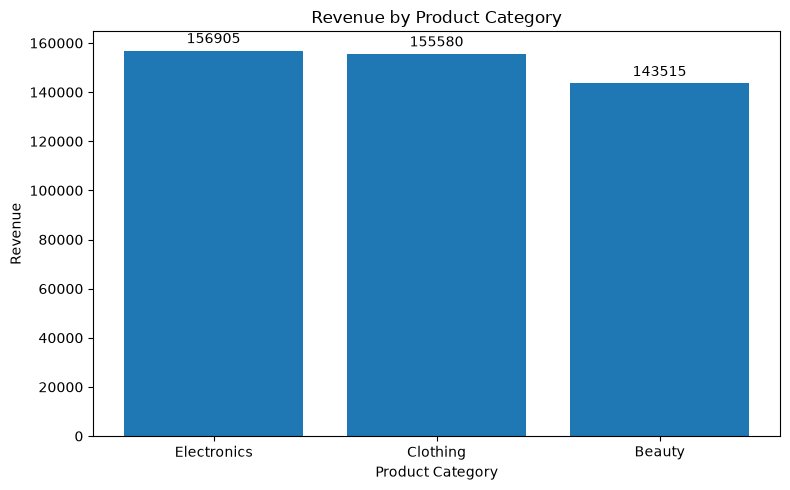

In [73]:
fig, ax = plt.subplots(figsize = (8,5))

bars = ax.bar(category_sales.index, category_sales.values)
ax.bar_label(bars, fmt = "%.0f", padding = 3)

ax.set_title("Revenue by Product Category")
ax.set_xlabel("Product Category")
ax.set_ylabel("Revenue")
plt.tight_layout()
plt.savefig("revenue_by_category.png", dpi=150, bbox_inches="tight")

In [56]:
#Extract year and month from the date
df["Year_Month"] = df["Date"].dt.to_period("M")

#Calculate revenue for each month
monthly_sales = (df.groupby("Year_Month")["Total Amount"].sum().sort_index())

print(monthly_sales)

Year_Month
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64


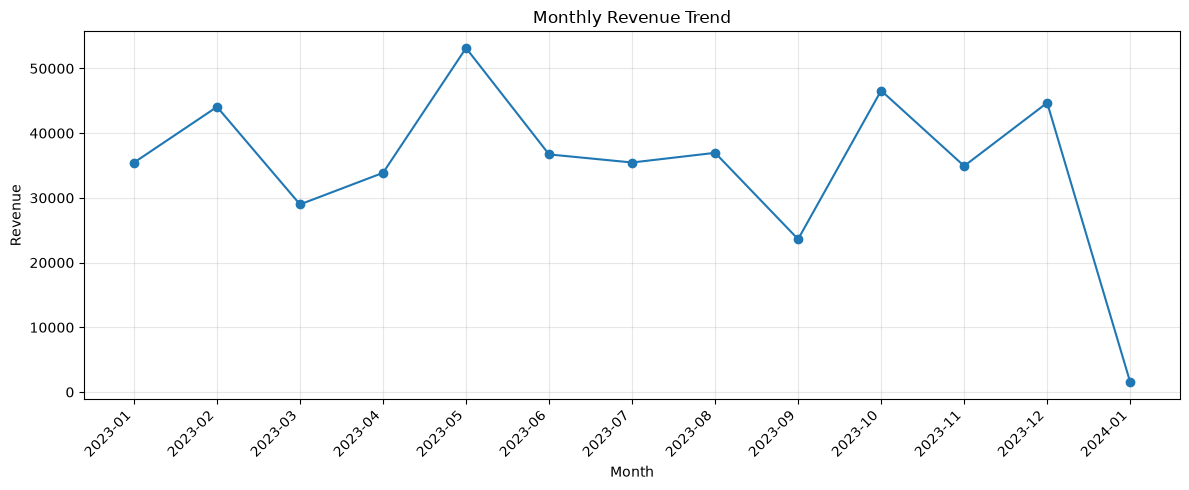

In [74]:

plt.figure(figsize = (12, 5))
plt.plot(monthly_sales.index.astype(str), monthly_sales.values, marker = "o")
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation = 45, ha = "right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("revenue_by_month.png", dpi=150, bbox_inches="tight")

In [72]:
#Check thedate range of the dataset 
print("First Date:", df["Date"].min())
print("Last Date:", df["Date"].max())

#Compare monthly revenue and transaction count
monthly_summary = (df.groupby("Year_Month").agg(
    Revenue = ("Total Amount", "sum"),
    Transactions = ("Transaction ID", "nunique"),
    Items_Sold = ("Quantity", "sum")
))
print(monthly_summary)                   

First Date: 2023-01-01 00:00:00
Last Date: 2024-01-01 00:00:00
            Revenue  Transactions  Items_Sold
Year_Month                                   
2023-01       35450            76         195
2023-02       44060            85         214
2023-03       28990            73         194
2023-04       33870            86         214
2023-05       53150           105         259
2023-06       36715            77         197
2023-07       35465            72         176
2023-08       36960            94         227
2023-09       23620            65         170
2023-10       46580            96         252
2023-11       34920            78         205
2023-12       44690            91         207
2024-01        1530             2           4
